# Actividad 1.2 · Aprendizaje por refuerzo: Q-Learning en el entorno Taxi
**Maestría en Inteligencia Artificial · TecNM Virtual** — Aprendizaje Automático Avanzado, Unidad 1  
**Autores:** Arturo Pérez y María D. Camacho · **Fecha:** octubre de 2026 · **Versión del modelo:** v1.0  
[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/artperezg/AA_Actividad1.2_Paradigmas/blob/main/notebooks/03_refuerzo_QLearning_Taxi.ipynb)

**Caso de estudio:** un taxi debe aprender, por prueba y error, a recoger a un pasajero y llevarlo a su destino por la ruta más corta.

| Punto de la actividad (Tarea 5) | Sección |
|---|---|
| Definición del entorno de aprendizaje | 1 |
| Entrenamiento del agente con el programa base de la unidad | 2 |
| Registro y gráfica de la recompensa acumulada | 3 |
| Evaluación del agente | 4 |
| Ajuste de un hiperparámetro principal (tasa de aprendizaje α) | 5 |

In [1]:
# Configuración: en Colab descarga el proyecto desde GitHub (no requiere Google Drive)
import sys, warnings, zipfile
from pathlib import Path

REPO_URL = "https://github.com/artperezg/AA_Actividad1.2_Paradigmas.git"
EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    RAIZ = Path("/content/AA_Actividad1.2_Paradigmas")
    if not RAIZ.exists():
        import subprocess
        r = subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(RAIZ)], capture_output=True, text=True)
        if r.returncode != 0:
            raise RuntimeError("No se pudo descargar el repositorio:\n" + r.stderr)
else:
    RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

RESULTADOS = RAIZ / "resultados" / "03_refuerzo"
MODELOS = RESULTADOS / "modelos"
MODELOS.mkdir(parents=True, exist_ok=True)
SEMILLA, VERSION_MODELO = 42, "v1.0"
print("Raíz del proyecto:", RAIZ)

Raíz del proyecto: /content/AA_Actividad1.2_Paradigmas


In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    import gymnasium as gym
except ImportError:                                   # se instala si no está disponible
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gymnasium"])
    import gymnasium as gym
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

def guardar_figura(nombre):
    ruta = RESULTADOS / f"{nombre}.png"
    plt.savefig(ruta, dpi=150, bbox_inches="tight")
    print("Figura guardada:", ruta.relative_to(RAIZ))

def crear_entorno(**kwargs):
    # Gymnasium 1.3 publica el entorno como Taxi-v4 (igual a Taxi-v3 en su versión determinista)
    for version in ("Taxi-v4", "Taxi-v3"):
        try:
            return gym.make(version, **kwargs)
        except Exception:
            continue
    raise RuntimeError("No se encontró el entorno Taxi en esta versión de Gymnasium")

## 1. Definición del entorno
Entorno **Taxi** de Gymnasium (continuación de OpenAI Gym), basado en Dietterich (2000).

| Elemento | Definición |
|---|---|
| Estado $s$ | Posición del taxi (5 × 5), ubicación del pasajero (4 paradas o dentro del taxi) y destino (4 paradas): **500 estados** |
| Acciones $a$ | **6**: sur, norte, este, oeste, recoger y dejar |
| Recompensa $r$ | −1 por paso; +20 por entregar al pasajero; −10 por recoger o dejar en un lugar incorrecto |
| Fin del episodio | Al entregar al pasajero, o a los 200 pasos |

In [3]:
entorno = crear_entorno(render_mode="ansi")
estado, _ = entorno.reset(seed=SEMILLA)
print("Entorno:", entorno.spec.id, "| Estados:", entorno.observation_space.n, "| Acciones:", entorno.action_space.n)
print(entorno.render())

Entorno: Taxi-v4 | Estados: 500 | Acciones: 6
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+




## 2. Programa base de la unidad
Es el programa de Q-Learning de la sección 3.1.4 con sus mismos hiperparámetros ($\alpha = 0.10$, $\gamma = 0.99$, ε de 1.0 a 0.05 con decaimiento de 0.999 y 15 000 episodios). Actualiza la tabla con

$$Q(s,a) \leftarrow Q(s,a) + \alpha\left[r + \gamma \max_{a'} Q(s',a') - Q(s,a)\right].$$

Los únicos cambios, marcados con `# CAMBIO`, son el entorno, el registro de la recompensa de cada episodio (lo pide la actividad) y las semillas para que el resultado sea reproducible.

In [4]:
def entrenar(alpha=0.10, semilla=SEMILLA):
    env = crear_entorno()                                  # CAMBIO: Taxi en lugar de FrozenLake
    n_states = env.observation_space.n
    n_actions = env.action_space.n
    Q = np.zeros((n_states, n_actions))
    gamma = 0.99
    epsilon = 1.0
    epsilon_min = 0.05
    epsilon_decay = 0.999
    episodes = 15000
    max_steps = 200
    rng = np.random.default_rng(semilla)
    env.action_space.seed(semilla)                         # CAMBIO: semilla de las acciones aleatorias
    recompensas = np.zeros(episodes)                       # CAMBIO: registro de la recompensa acumulada

    def epsilon_greedy(state, eps):
        if rng.random() < eps:
            return env.action_space.sample()
        return int(np.argmax(Q[state]))

    env.reset(seed=semilla)                                # CAMBIO: semilla del entorno
    for ep in range(episodes):
        state, _ = env.reset()
        for _ in range(max_steps):
            action = epsilon_greedy(state, epsilon)
            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
            best_next = np.max(Q[next_state])
            td_target = reward + gamma * best_next
            td_error = td_target - Q[state, action]
            Q[state, action] += alpha * td_error
            state = next_state
            recompensas[ep] += reward                      # CAMBIO
            if done:
                break
        epsilon = max(epsilon_min, epsilon * epsilon_decay)
    env.close()
    return Q, recompensas


def evaluar(Q, test_episodes=200, max_steps=200):
    # Evaluación sin exploración (igual que en el programa base)
    env = crear_entorno()
    env.reset(seed=1000)
    success, total, pasos = 0, [], []
    for _ in range(test_episodes):
        state, _ = env.reset()
        suma = 0
        for t in range(max_steps):
            state, reward, terminated, truncated, _ = env.step(int(np.argmax(Q[state])))
            suma += reward
            if terminated or truncated:
                success += int(reward == 20)               # CAMBIO: en Taxi la entrega exitosa da +20
                break
        total.append(suma); pasos.append(t + 1)
    env.close()
    return success / test_episodes, np.mean(total), np.mean(pasos)

media_movil = lambda x, w=100: pd.Series(x).rolling(w, min_periods=1).mean().to_numpy()

## 3. Entrenamiento y evolución de la recompensa acumulada

Entrenamiento: 15 000 episodios en 4 s
  Episodio    100: recompensa media (últimos 100) =   -733.7
  Episodio   1000: recompensa media (últimos 100) =    -71.1
  Episodio   2000: recompensa media (últimos 100) =     -1.6
  Episodio   3000: recompensa media (últimos 100) =      5.5
  Episodio   5000: recompensa media (últimos 100) =      5.4
  Episodio  15000: recompensa media (últimos 100) =      5.1


Figura guardada: resultados/03_refuerzo/01_recompensa_acumulada.png


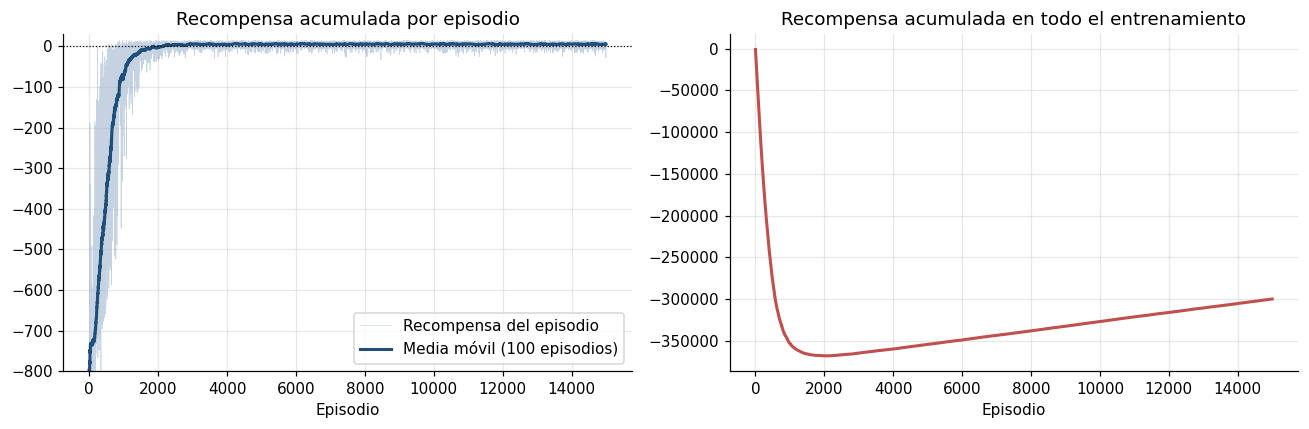

In [5]:
inicio = time.time()
Q, recompensas = entrenar()
print(f"Entrenamiento: 15 000 episodios en {time.time() - inicio:.0f} s")
mm = media_movil(recompensas)
for ep in [100, 1000, 2000, 3000, 5000, 15000]:
    print(f"  Episodio {ep:>6}: recompensa media (últimos 100) = {mm[ep - 1]:8.1f}")
pd.DataFrame({"episodio": np.arange(1, 15001), "recompensa": recompensas}).to_csv(RESULTADOS / "recompensas_entrenamiento.csv", index=False)

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].plot(recompensas, color="#9db4d0", lw=0.4, alpha=0.6, label="Recompensa del episodio")
ejes[0].plot(mm, color="#1f4e79", lw=2, label="Media móvil (100 episodios)")
ejes[0].axhline(0, color="k", ls=":", lw=0.8); ejes[0].set_ylim(-800, 30)
ejes[0].set_title("Recompensa acumulada por episodio"); ejes[0].set_xlabel("Episodio"); ejes[0].legend(loc="lower right")
ejes[1].plot(np.cumsum(recompensas), color="#c0504d", lw=2)
ejes[1].set_title("Recompensa acumulada en todo el entrenamiento"); ejes[1].set_xlabel("Episodio")
plt.tight_layout()
guardar_figura("01_recompensa_acumulada")
plt.show()
np.save(MODELOS / f"q_table_taxi_{VERSION_MODELO}.npy", Q)

- Al inicio el agente actúa casi al azar: la recompensa media es de −734 por episodio, por los muchos pasos y las acciones ilegales.
- La media móvil cruza 0 alrededor del episodio 2 000 y se estabiliza en ≈ +5 a partir del 3 000, cuando ε llega a su mínimo (0.05).
- La recompensa acumulada total baja mientras el agente explora y empieza a subir cuando su política ya es buena.

## 4. Evaluación del agente

In [6]:
exito, recompensa_media, pasos_medios = evaluar(Q)
print(f"Tasa de éxito: {exito:.1%} | Recompensa media: {recompensa_media:.2f} | Pasos por episodio: {pasos_medios:.1f}")

Tasa de éxito: 100.0% | Recompensa media: 7.98 | Pasos por episodio: 13.0


Sin exploración, el agente entrega al pasajero en el **100 %** de los 200 episodios, con 13.0 pasos y una recompensa media de +7.98 por episodio.

## 5. Ajuste del hiperparámetro α (tasa de aprendizaje)
Se entrena con $\alpha \in \{0.01,\ 0.10,\ 0.50\}$, manteniendo los demás hiperparámetros del programa base. Cada valor se repite con 5 semillas para descartar resultados por azar (≈ 3–5 min).

Figura guardada: resultados/03_refuerzo/02_ajuste_alpha.png


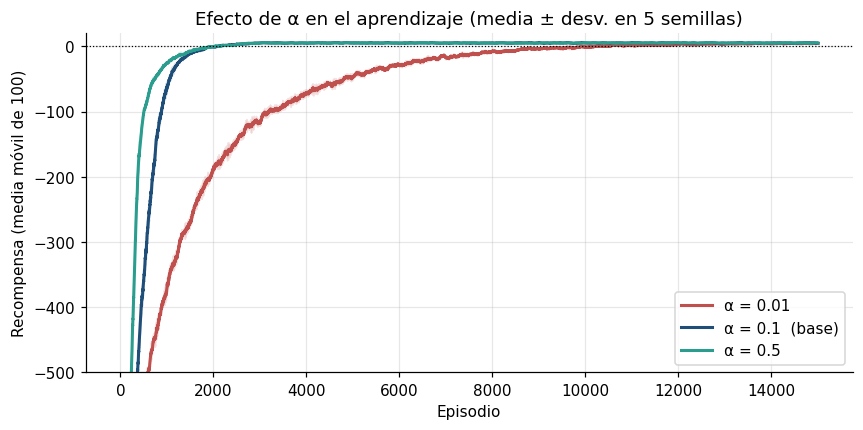

,α,recompensa media (últimos 1000 episodios),episodio en que la media supera 0,tasa de éxito en evaluación
0,0.01,4.43,9172.4,0.86
1,0.10,5.30,2018.2,1.00
2,0.50,5.25,1978.2,1.00


In [7]:
SEMILLAS = [0, 1, 2, 3, 4]
filas, curvas = [], {}
for alpha in [0.01, 0.10, 0.50]:
    mms, finales, cruces, exitos = [], [], [], []
    for s in SEMILLAS:
        Q_a, r_a = entrenar(alpha=alpha, semilla=s)
        mm_a = media_movil(r_a)
        mms.append(mm_a)
        finales.append(r_a[-1000:].mean())
        cruce = np.where(pd.Series(r_a).rolling(100).mean().to_numpy() >= 0)[0]
        cruces.append(cruce[0] + 1 if len(cruce) else np.nan)
        exitos.append(evaluar(Q_a)[0])
    curvas[alpha] = np.array(mms)
    filas.append({"α": alpha, "recompensa media (últimos 1000 episodios)": np.mean(finales),
                  "episodio en que la media supera 0": np.nanmean(cruces), "tasa de éxito en evaluación": np.mean(exitos)})
tabla_alpha = pd.DataFrame(filas).round(2)
tabla_alpha.to_csv(RESULTADOS / "ajuste_alpha.csv", index=False)

plt.figure(figsize=(9, 4))
for (alpha, mms), color in zip(curvas.items(), ["#c0504d", "#1f4e79", "#2a9d8f"]):
    plt.plot(mms.mean(axis=0), color=color, lw=2, label=f"α = {alpha}" + ("  (base)" if alpha == 0.10 else ""))
    plt.fill_between(np.arange(15000), mms.mean(0) - mms.std(0), mms.mean(0) + mms.std(0), color=color, alpha=0.15)
plt.axhline(0, color="k", ls=":", lw=0.8); plt.ylim(-500, 20)
plt.xlabel("Episodio"); plt.ylabel("Recompensa (media móvil de 100)")
plt.title("Efecto de α en el aprendizaje (media ± desv. en 5 semillas)"); plt.legend(loc="lower right")
guardar_figura("02_ajuste_alpha")
plt.show()
tabla_alpha

- **α = 0.01** aprende muy lento: la recompensa media supera 0 hasta el episodio ≈ 9 170 y solo logra 86 % de éxito en la evaluación.
- **α = 0.10** (base) y **α = 0.50** superan 0 en ≈ 2 000 episodios y logran 100 % de éxito. α = 0.50 aprende más rápido al principio porque Taxi es determinista: no hay ruido que promediar.
- **Para la versión v1.0 se conserva α = 0.10** (el valor del programa base), que alcanza el mismo desempeño final que α = 0.50.

In [8]:
import platform
print("Python", platform.python_version(), "| gymnasium", gym.__version__, "| numpy", np.__version__)

Python 3.12.3 | gymnasium 1.3.0 | numpy 2.4.4
